# 3h→逐小时：调度 CLI 并计算 RMSE

对 `resource/EC/APCP` 的 **0 起报累计降水** 调用 TimeSplit CLI：插成逐小时累计后再 `delta=1` 得到分段小时降水，与 `CMPAS_APCP_Hourly` 在 **重合 0.1° 格点** 上算 RMSE；同时按约定给出原数据基线（`(C(t)-C(t-3))/3`）。

在本包根目录 `time_split_linear` 下打开本笔记本，或保证该目录在 `sys.path` 中。

## 可对齐时窗

| 数据 | 覆盖 |
|---|---|
| EC `APCP` | 起报 **2026-07-27 00 UTC**，时效 0,3,…,24（从 0 起累计） |
| `CMPAS_APCP_Hourly` | BJT 0727 00–23、0728 00–23 |
| `CMPA_RT_10MIN`（本笔记暂不用） | 仅 BJT 0727 **12:00–23:50** |

时区：实况 BJT = UTC+8。分段小时时效 `h`（降水在 `[h-1,h]`）对应

- 有效时刻 UTC = 起报 + `h`
- 实况文件 BJT = 该 UTC + 8h

因此 **逐小时 vs CMPAS**：时效 **1–24 全部可对齐**（lead1→BJT 0727 09 … lead24→BJT 0728 08）。

若以后做 10min，重叠大约是 UTC 04–15（BJT 12–23），对应粗略时效 4–15 一段。

In [1]:
from __future__ import annotations

import sys
from datetime import datetime, timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import meteva_base as meb

ROOT = Path.cwd().resolve()
if not (ROOT / "cli").is_dir():
    # 若从 nbs/ 启动，回到包根
    if (ROOT.parent / "cli").is_dir():
        ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from cli.cal_griddata_TimeSplit_plugin_cli import process

ISSUE = datetime(2026, 7, 27, 0)  # UTC
ISSUE_STR = ISSUE.strftime("%Y%m%d%H")
INPUT_FMT = str(ROOT / "resource" / "EC" / "APCP" / "YYYY" / "YYYYMMDD" / "YYYYMMDDHH.TTT.nc")
OBS_ROOT = ROOT / "resource" / "CMPAS_APCP_Hourly"

print("ROOT", ROOT)
print("issue UTC", ISSUE_STR)
print("input_fmt", INPUT_FMT)

d:\workspace\test\.venv\Lib\site-packages\meteva_base\basicdata\const.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


ROOT D:\workspace\test\00temp\time_split_linear
issue UTC 2026072700
input_fmt D:\workspace\test\00temp\time_split_linear\resource\EC\APCP\YYYY\YYYYMMDD\YYYYMMDDHH.TTT.nc


## 调度 CLI（3h→逐小时分段）

等价命令行（在包根执行）：

```bash
python -m cli.cal_griddata_TimeSplit_plugin_cli \
  --input-fh 0,24,3 --output-fh 0,24,1 --delta 1 \
  --input-fmt resource/EC/APCP/YYYY/YYYYMMDD/YYYYMMDDHH.TTT.nc \
  --time 2026072700
```

下面直接调模块级 `process`（与 CLI 同一条路径）。默认 `slinear`/`linear` 时，同一 3h 窗内各小时分段量恒等于 `(C_end-C_start)/3`，故方法 RMSE 与基线 RMSE 会相同——这是线性插值的数学结果，不是算重了。

若改成非线性时间插值（如 `cubic`），窗内小时增量一般不再均匀，方法场才会与基线分开；但累计降水上用高阶插值可能出现超调、差分后出现负降水，需另行约束。

In [2]:
fine, raw = process(
    input_fh="0,24,3",
    output_fh="0,24,1",
    input_fmt=INPUT_FMT,
    time=ISSUE_STR,
    delta="1",
    is_fill0=False,
    is_min=False,
    index="dtime",
)
assert fine is not None and raw is not None, "CLI process 失败"
print("fine dtime", list(map(int, fine.dtime.values)))
print("raw  dtime", list(map(int, raw.dtime.values)))

Read FILE:  0 2026-07-27 00:00:00 0 D:\workspace\test\00temp\time_split_linear\resource\EC\APCP\2026\20260727\2026072700.000.nc
Read FILE:  5 2026-07-27 00:00:00 15 D:\workspace\test\00temp\time_split_linear\resource\EC\APCP\2026\20260727\2026072700.015.nc
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 9, lat: 601,
                           lon: 801)> Size: 17MB
array([[[[[[ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           ...,
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ]],

          [[ 2.7,  2.3,  1.4, ...,  0. ,  0. ,  0. ],
           [ 2.6,  2.8,  1.6, ...,  0. ,  0. ,  0. ],
           [ 2.4,  1.9,  1.8, ...,  0. ,  0. ,  0. ],
           ...,
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0

## 原数据基线与实况抽点

- **基线**：近 3h **时段累计**再除以 3，得到该窗内统一的小时量。对时效 `h`，取窗末端 `t=ceil(h/3)*3`，`baseline=(APCP(t)-APCP(t-3))/3`；窗内 1/2/3h 共用同一场。
- **RMSE**：在重合 0.1° 格点上，`RMSE = sqrt(mean((预报 − 实况)^2))`。
  - `rmse_method`：TimeSplit 分段小时场 vs 对应时次 `CMPAS`
  - `rmse_baseline`：上述 3h 平均小时场 vs **同一时次** `CMPAS`
  - 打印的「基线 RMSE 平均」= 各对齐时效 `rmse_baseline` 的算术平均（对 lead 1–24）
- 实况抽点：BJT 读 `CMPAS`，只在预报 lon/lat 重叠区索引取值，不加密预报网格。

In [3]:
def rmse(a: np.ndarray, b: np.ndarray) -> float:
    m = np.isfinite(a) & np.isfinite(b)
    if not np.any(m):
        return float("nan")
    d = a[m] - b[m]
    return float(np.sqrt(np.mean(d * d)))


def cum_to_baseline(raw_da, lead: int) -> np.ndarray:
    """降水原数据基线：(C(t)-C(t-3))/3，t 为 lead 所在 3h 窗末端。"""
    t = int(np.ceil(lead / 3.0) * 3)
    if t < 3:
        raise ValueError(f"lead={lead} 无法构造 3h 基线")
    c_t = np.asarray(raw_da.sel(dtime=t).values, dtype=float)
    c_0 = np.asarray(raw_da.sel(dtime=t - 3).values, dtype=float)
    return (c_t - c_0) / 3.0


def obs_path_for_lead(lead: int) -> Path:
    valid_utc = ISSUE + timedelta(hours=int(lead))
    bjt = valid_utc + timedelta(hours=8)
    return OBS_ROOT / f"{bjt:%Y}" / f"{bjt:%Y%m%d}" / f"BJT_{bjt:%y%m%d%H}.000.nc"


def sample_obs_on_fcst_grid(obs_da, lon_need: np.ndarray, lat_need: np.ndarray) -> np.ndarray:
    """在重合点按等经纬步长索引抽取实况（预报格点不变）。"""
    olon = np.asarray(obs_da.lon.values, dtype=float)
    olat = np.asarray(obs_da.lat.values, dtype=float)
    dlon = float(olon[1] - olon[0])
    dlat = float(olat[1] - olat[0])
    i_lon = np.round((lon_need - olon[0]) / dlon).astype(int)
    i_lat = np.round((lat_need - olat[0]) / dlat).astype(int)
    if np.any((i_lon < 0) | (i_lon >= olon.size)) or np.any((i_lat < 0) | (i_lat >= olat.size)):
        raise IndexError("预报格点超出实况网格范围")
    vals = np.asarray(obs_da.values, dtype=float).reshape(olat.size, olon.size)
    return vals[np.ix_(i_lat, i_lon)]


lon_f = np.asarray(fine.lon.values, dtype=float)
lat_f = np.asarray(fine.lat.values, dtype=float)
lon_m = (lon_f >= 70.0 - 1e-8) & (lon_f <= 140.0 + 1e-8)
lat_m = (lat_f >= 0.0 - 1e-8) & (lat_f <= 60.0 + 1e-8)
lon_need = lon_f[lon_m]
lat_need = lat_f[lat_m]

rows = []
for lead in map(int, fine.dtime.values):
    op = obs_path_for_lead(lead)
    if not op.is_file():
        rows.append(
            {
                "lead": lead,
                "bjt_file": op.name,
                "ok": False,
                "rmse_method": np.nan,
                "rmse_baseline": np.nan,
            }
        )
        continue
    obs = meb.read_griddata_from_nc(str(op))
    obs_s = sample_obs_on_fcst_grid(obs, lon_need, lat_need)
    fc = np.squeeze(
        np.asarray(fine.sel(dtime=lead, lon=lon_need, lat=lat_need).values, dtype=float)
    )
    base = np.squeeze(cum_to_baseline(raw, lead))[np.ix_(lat_m, lon_m)]
    rows.append(
        {
            "lead": lead,
            "bjt_file": op.name,
            "ok": True,
            "rmse_method": rmse(fc, obs_s),
            "rmse_baseline": rmse(base, obs_s),
            "mean_method": float(np.nanmean(fc)),
            "mean_baseline": float(np.nanmean(base)),
            "mean_obs": float(np.nanmean(obs_s)),
        }
    )

df = pd.DataFrame(rows)
# 指标表只在下一格打印一次，这里不再显示 df

In [4]:
ok = df["ok"]
print("对齐时效数", int(ok.sum()), "/", len(df))
print("方法 RMSE 平均", float(df.loc[ok, "rmse_method"].mean()))
print("基线 RMSE 平均", float(df.loc[ok, "rmse_baseline"].mean()))
print("方法与基线 RMSE 最大差", float(np.nanmax(np.abs(df.loc[ok, "rmse_method"] - df.loc[ok, "rmse_baseline"]))))
df.loc[ok, ["lead", "rmse_method", "rmse_baseline", "mean_method", "mean_baseline", "mean_obs"]]

对齐时效数 24 / 24
方法 RMSE 平均 1.172679510146484
基线 RMSE 平均 1.1726795102735246
方法与基线 RMSE 最大差 4.950533316616657e-10


,lead,rmse_method,rmse_baseline,mean_method,mean_baseline,mean_obs
0,1,0.877236,0.877236,0.229930,0.229930,0.185279
1,2,0.924997,0.924997,0.229930,0.229930,0.204890
2,3,0.885463,0.885463,0.229930,0.229930,0.200168
3,4,0.888094,0.888094,0.302251,0.302251,0.195758
4,5,0.969558,0.969558,0.302251,0.302251,0.223199
5,6,0.978083,0.978083,0.302251,0.302251,0.247670
6,7,1.214686,1.214686,0.354835,0.354835,0.256041
7,8,1.287421,1.287421,0.354835,0.354835,0.268582
8,9,1.410719,1.410719,0.354835,0.354835,0.294428
9,10,1.395642,1.395642,0.273203,0.273203,0.286907


## 画图：0–3h 窗内插值 1h、2h 与实况

只看第一个 3h 窗。用 `meb.pcolormesh_2d_grid` 出图；降水分级与 `cmap="rain_1h"` 对齐 `orographic_precipitation_downscaling/nbs/batch_redistribute_and_verify.ipynb`。线性插值下 1h 与 2h 场应相同；lead1→BJT 09、lead2→BJT 10。

rain_clevs [0, 0.1, 1, 2, 4, 8, 16, 32]
bias_clevs [np.float64(-2.5), np.float64(-2.0), np.float64(-1.5), np.float64(-1.0), np.float64(-0.5), np.float64(0.0), np.float64(0.5), np.float64(1.0), np.float64(1.5), np.float64(2.0), np.float64(2.5)]


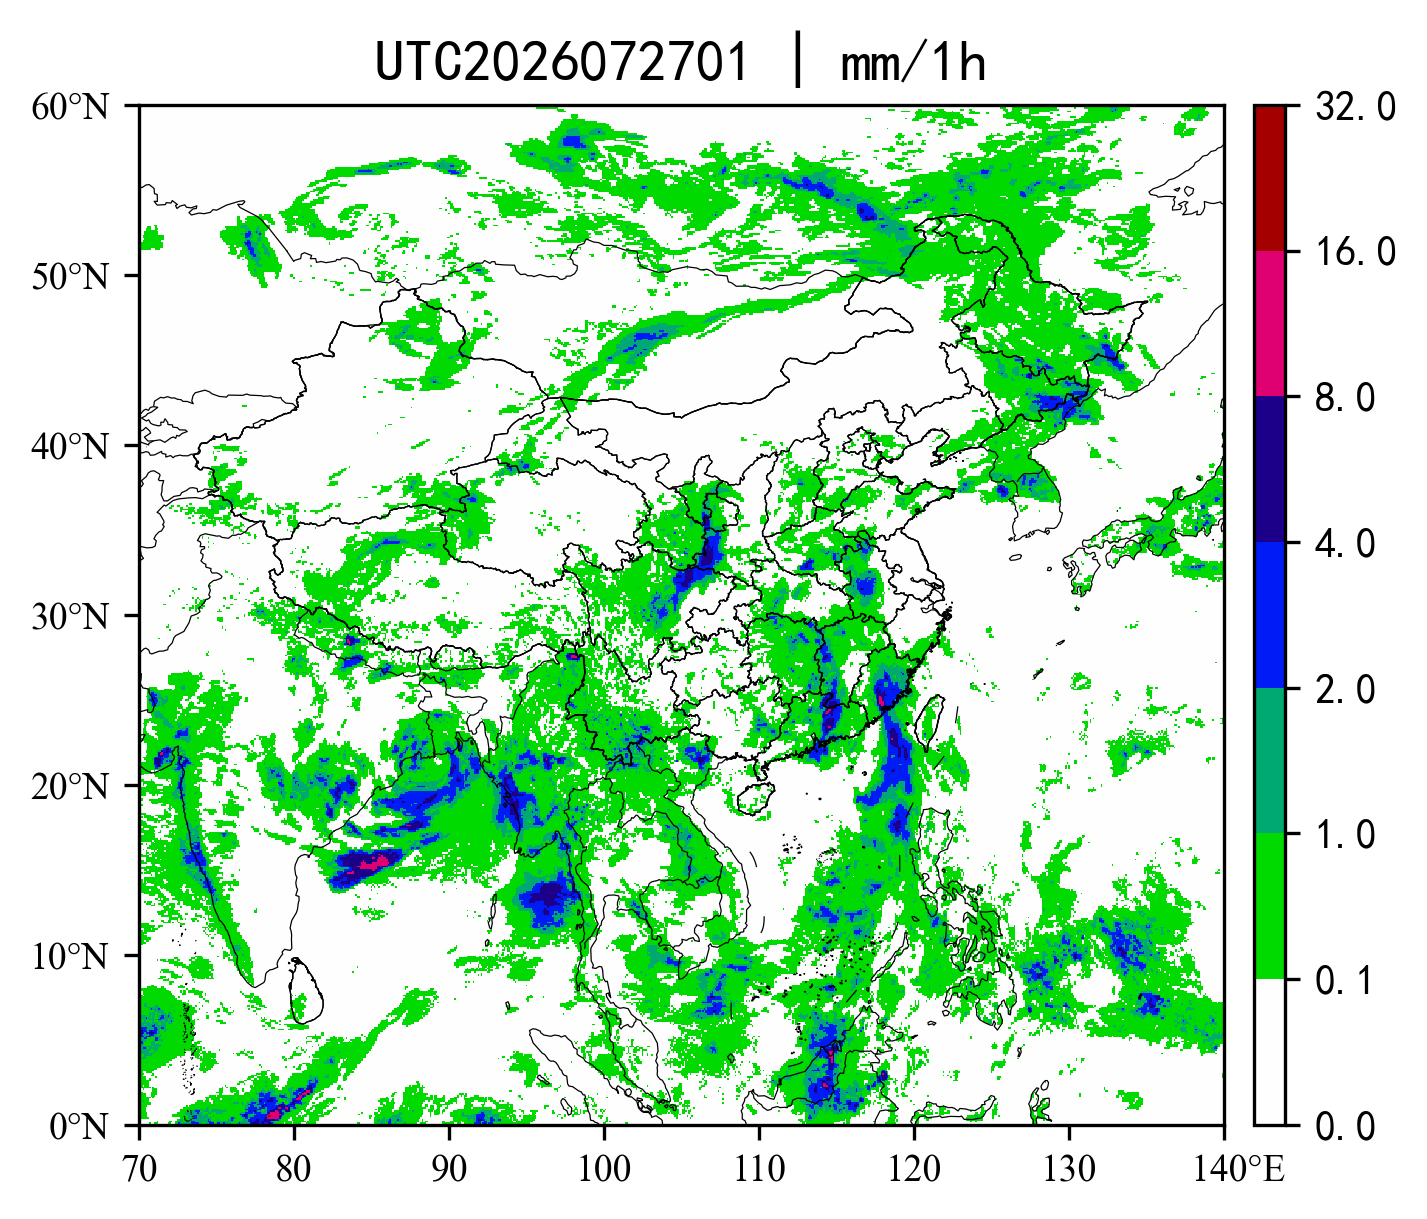

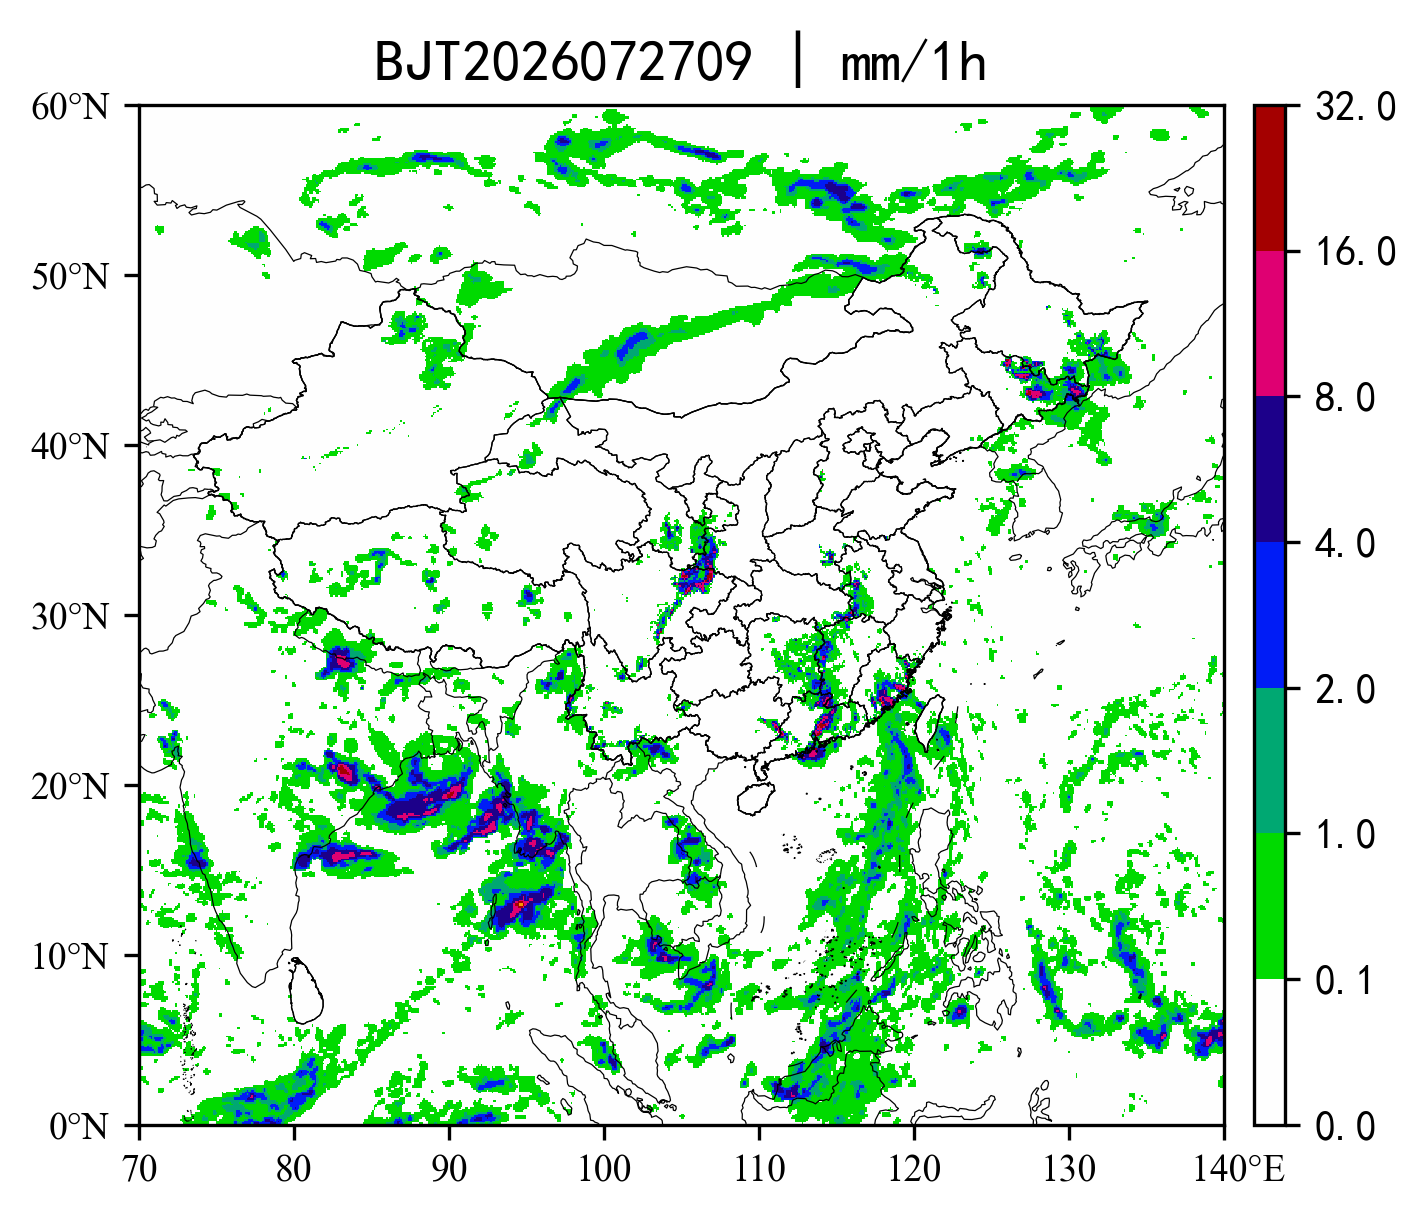

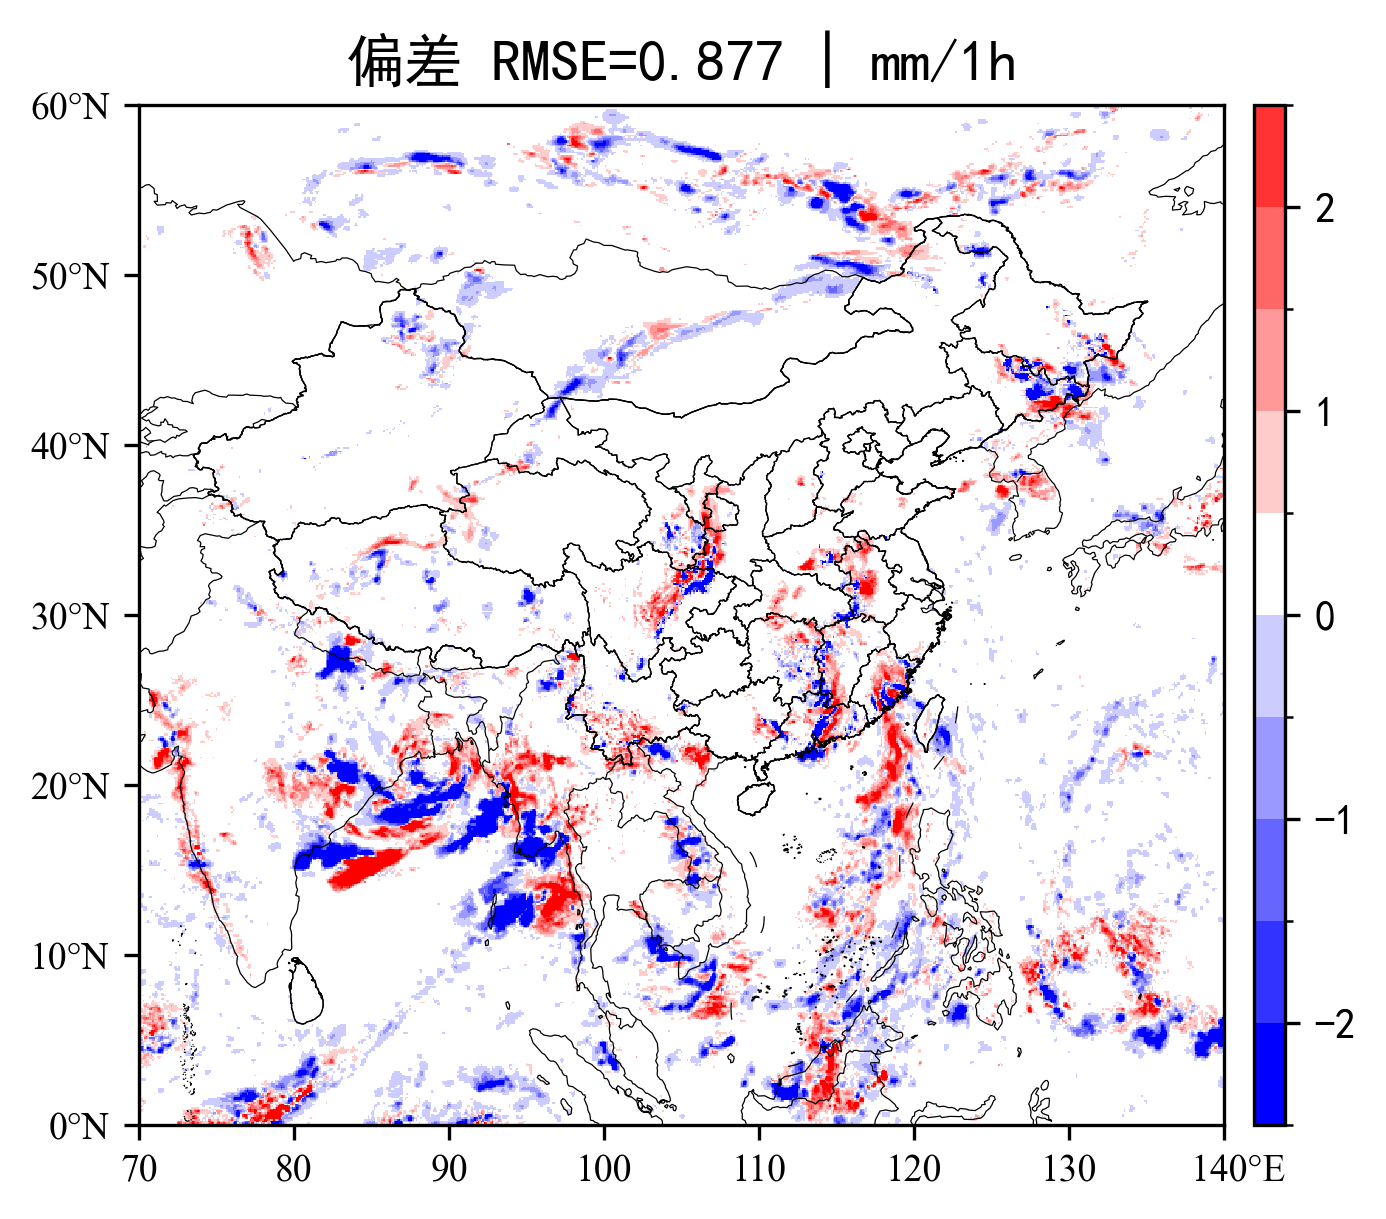

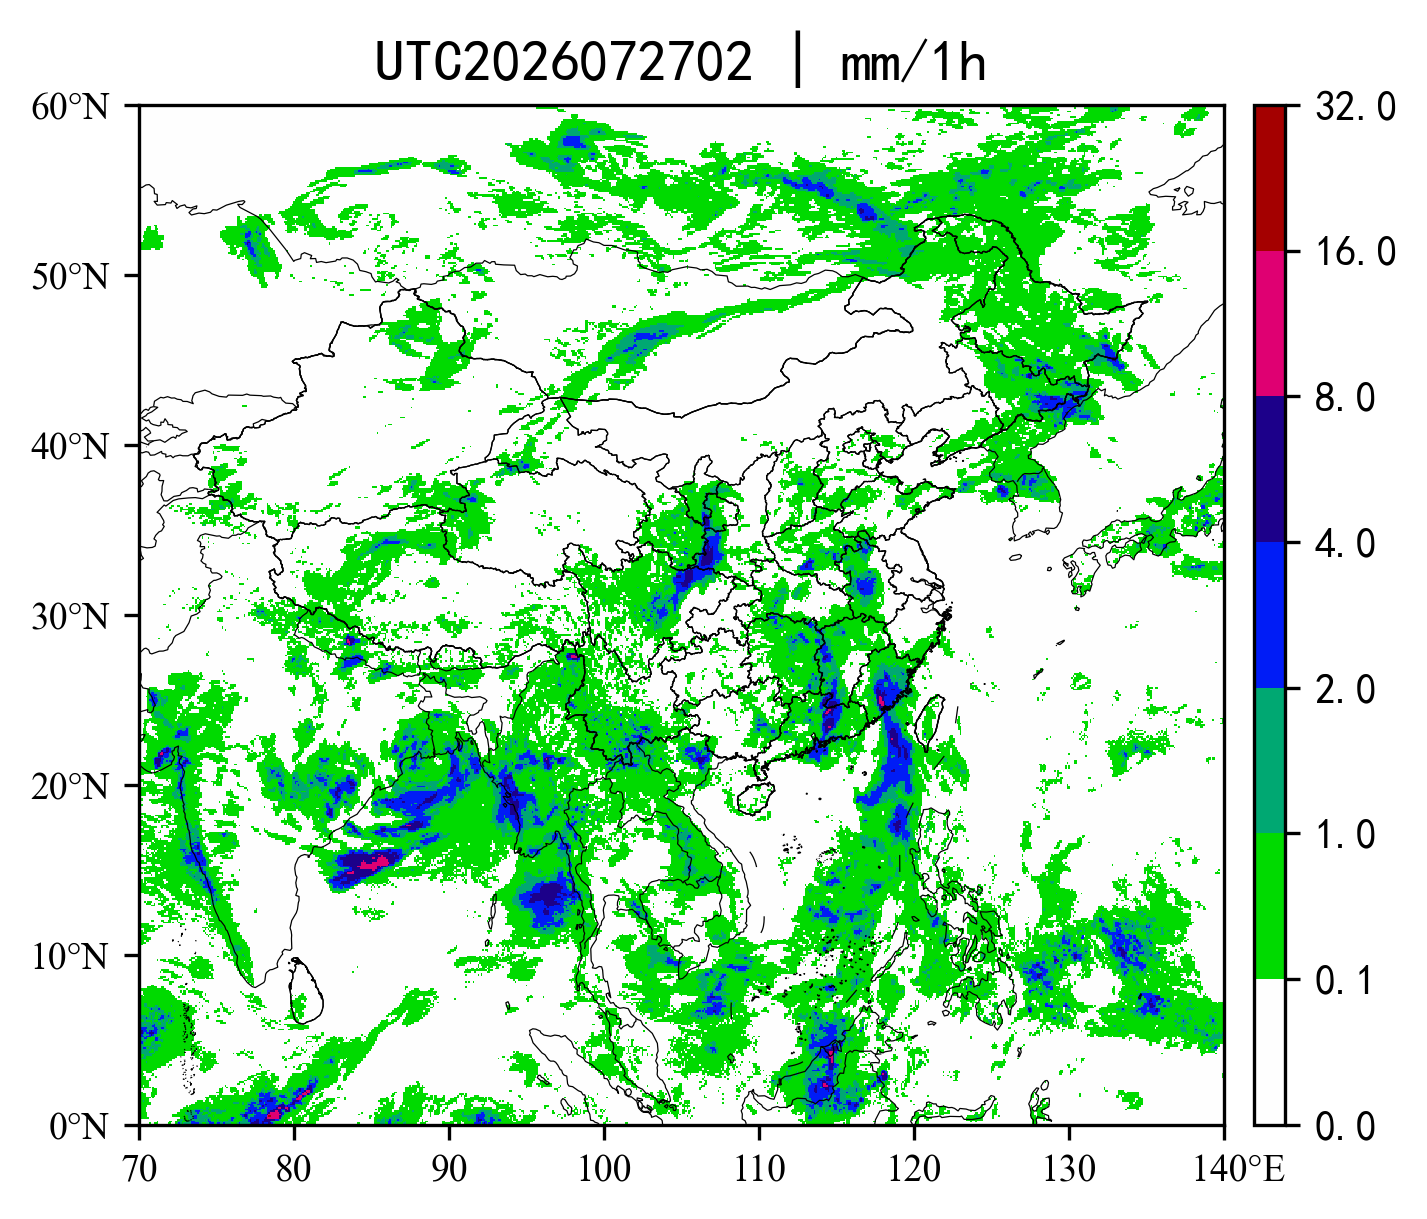

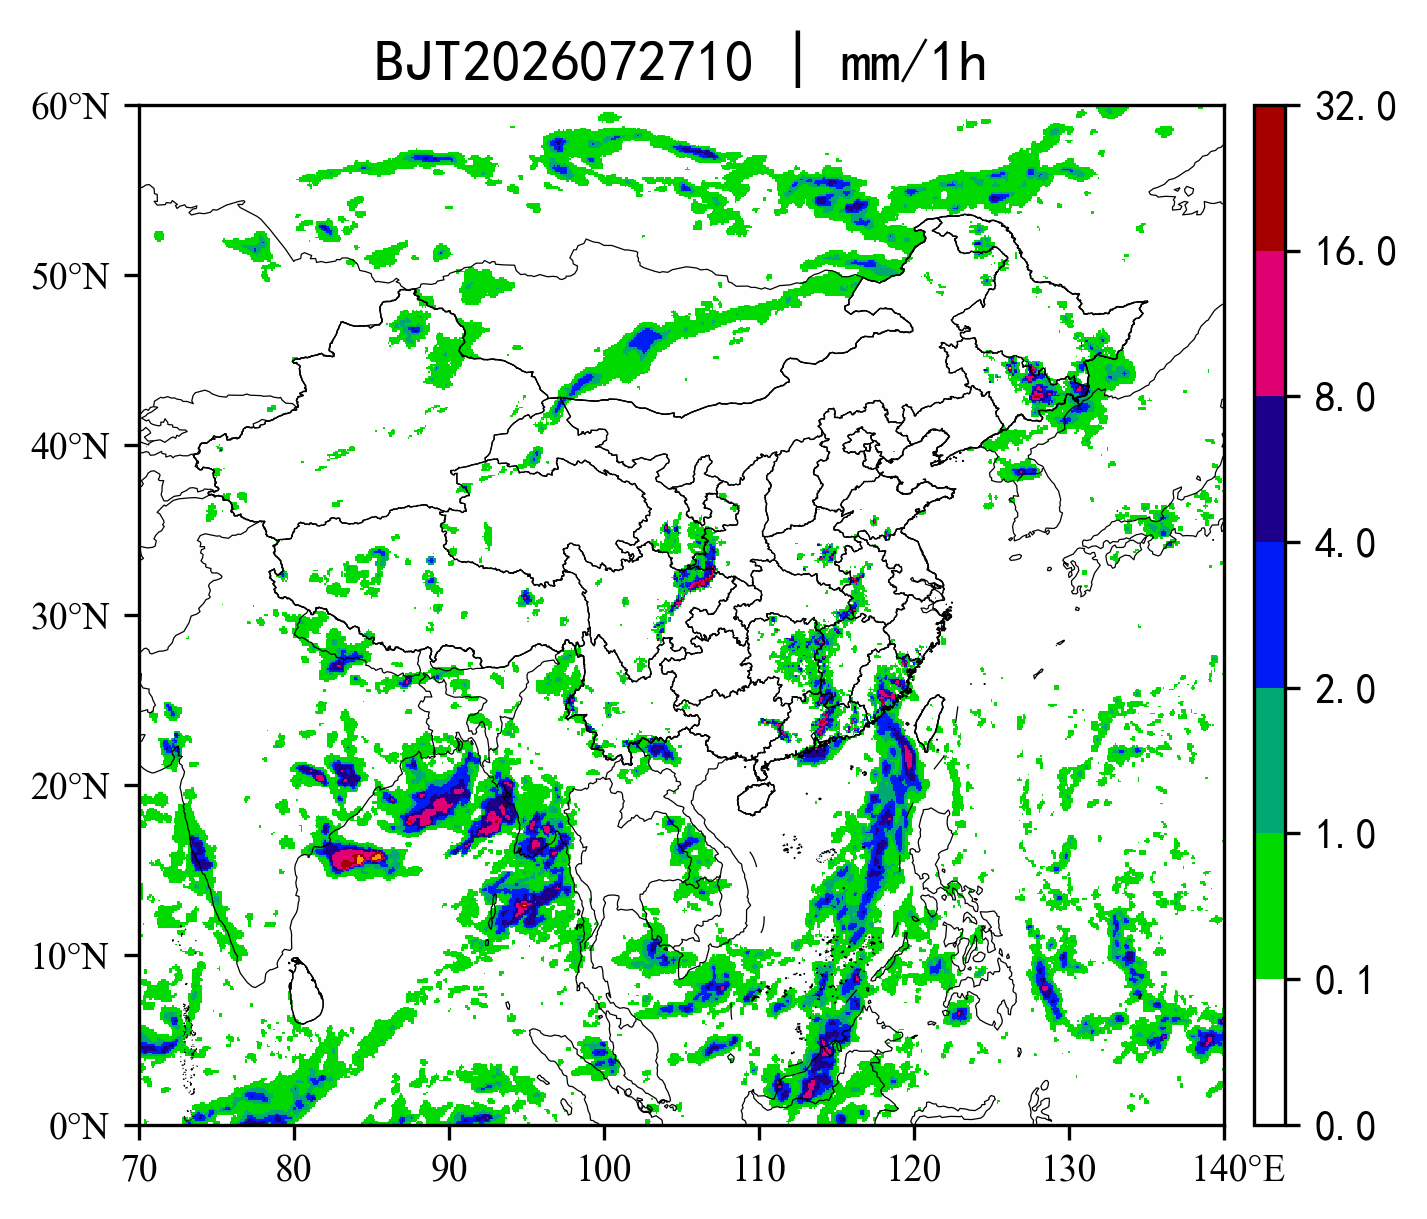

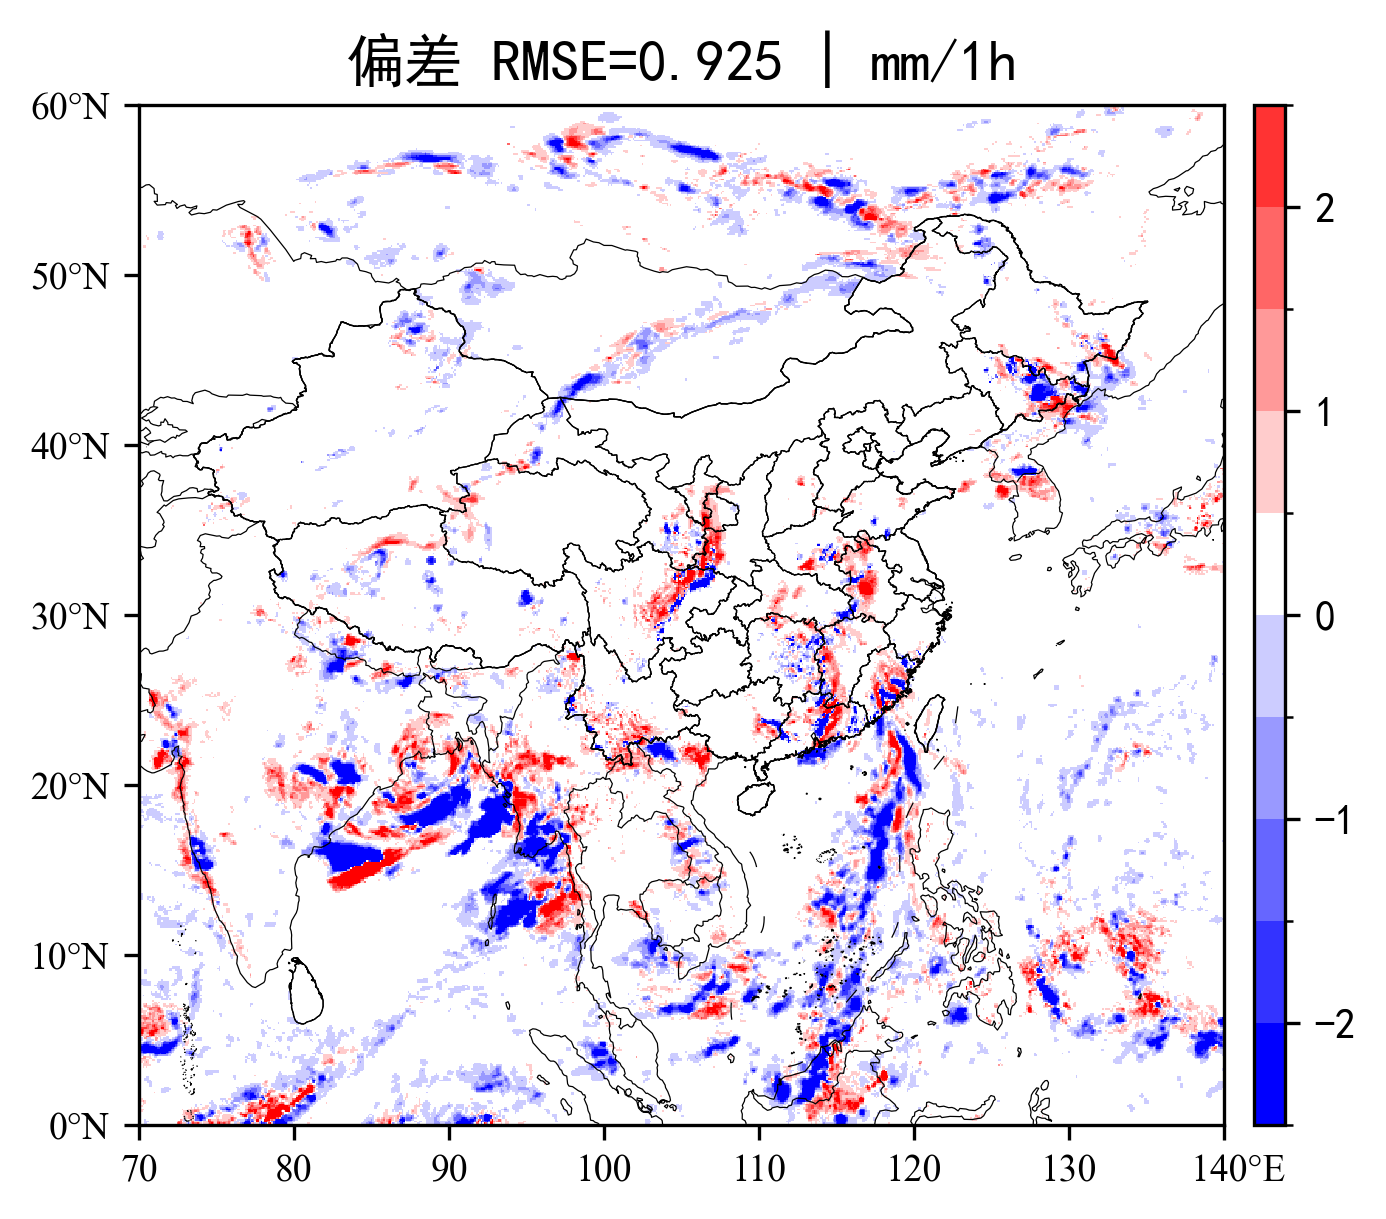

figures -> D:\workspace\test\00temp\time_split_linear\nbs\figs_verify_3h_to_hourly


In [5]:
from meteva_base.tool.plot_tools import pcolormesh_2d_grid

PLOT_LEADS = (1, 2)
FIG_DIR = ROOT / "nbs" / "figs_verify_3h_to_hourly"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def _plottable(da):
    v = np.asarray(da.values, dtype=float)
    ok = np.isfinite(v) & (np.abs(v) < 1e10)
    if np.all(ok) or not np.any(ok):
        return da
    fill = float(np.min(v[ok]))
    return da.copy(data=np.where(ok, v, fill).astype(np.float32))


def _auto_clevs(fields, n=11, symmetric=False, nonnegative=False):
    if not isinstance(fields, (list, tuple)):
        fields = [fields]
    vals = np.concatenate([np.asarray(da.values, dtype=float).ravel() for da in fields])
    vals = vals[np.isfinite(vals) & (np.abs(vals) < 1e10)]
    if nonnegative:
        vals = vals[vals >= 0]
    if vals.size == 0:
        return [-1.0, 0.0, 1.0] if symmetric else [0.0, 1.0]
    if symmetric:
        hi = max(float(np.nanpercentile(np.abs(vals), 98)), 1e-6)
        return list(np.linspace(-hi, hi, n))
    if nonnegative:
        hi = max(float(np.nanpercentile(vals, 99)), 1.0)
        clevs = [0, 0.1, 1, 2, 4, 8, 16, 32]
        while clevs[-1] < hi and len(clevs) < 19:
            clevs.append(clevs[-1] * 2)
        return clevs
    lo = float(np.nanpercentile(vals, 2))
    hi = float(np.nanpercentile(vals, 98))
    if not np.isfinite(lo) or not np.isfinite(hi) or abs(hi - lo) < 1e-12:
        mid = float(np.nanmedian(vals)) if vals.size else 0.0
        return [mid - 1.0, mid, mid + 1.0]
    return list(np.linspace(lo, hi, n))


def _as_overlap_grid(lead: int, values_2d: np.ndarray):
    """把 (lat, lon) 数组挂到与 fine 重叠区相同的 meteva 格点壳上。"""
    tmpl = fine.sel(dtime=lead, lon=lon_need, lat=lat_need)
    out = tmpl.copy(deep=True)
    out.values[:] = np.asarray(values_2d, dtype=np.float32).reshape(out.shape)
    return out


def _show(da, title, fname, *, cmap=None, clevs=None):
    field = _plottable(da)
    kw = dict(save_path=str(FIG_DIR / fname), title=title, clevs=clevs, show=True)
    if cmap is not None:
        kw["cmap"] = cmap
    pcolormesh_2d_grid(field, **kw)


panels = []
for lead in PLOT_LEADS:
    op = obs_path_for_lead(lead)
    obs = meb.read_griddata_from_nc(str(op))
    obs_s = sample_obs_on_fcst_grid(obs, lon_need, lat_need)
    fc_da = fine.sel(dtime=lead, lon=lon_need, lat=lat_need)
    fc_2d = np.squeeze(np.asarray(fc_da.values, dtype=float))
    obs_da = _as_overlap_grid(lead, obs_s)
    diff_da = _as_overlap_grid(lead, fc_2d - obs_s)
    bjt = ISSUE + timedelta(hours=int(lead) + 8)
    panels.append(
        {
            "lead": lead,
            "bjt": bjt,
            "fc": fc_da,
            "obs": obs_da,
            "diff": diff_da,
            "rmse": rmse(fc_2d, obs_s),
        }
    )

rain_clevs = _auto_clevs([p["fc"] for p in panels] + [p["obs"] for p in panels], nonnegative=True)
bias_clevs = _auto_clevs([p["diff"] for p in panels], symmetric=True)
print("rain_clevs", rain_clevs)
print("bias_clevs", [round(x, 3) for x in bias_clevs])

for p in panels:
    lead = p["lead"]
    bjt = p["bjt"]
    _show(
        p["fc"],
        f"UTC{(ISSUE+timedelta(hours=int(lead))):%Y%m%d%H} | mm/1h",
        f"lead{lead}_fc.png",
        cmap="rain_1h",
        clevs=rain_clevs,
    )
    _show(
        p["obs"],
        f"BJT{bjt:%Y%m%d%H} | mm/1h",
        f"lead{lead}_obs.png",
        cmap="rain_1h",
        clevs=rain_clevs,
    )
    _show(
        p["diff"],
        f"偏差 RMSE={p['rmse']:.3f} | mm/1h",
        f"lead{lead}_bias.png",
        cmap="bwr",
        clevs=bias_clevs,
    )

print("figures ->", FIG_DIR)


## 3h→逐 10min：调度 CLI 并计算 RMSE

输入仍是 **`APCP` 从 0 起的累计**（不是 `APCP01` 分段、也不是上一节 `delta=1` 的小时分段结果）。
在累计轴上插到分钟，再按 10min 差分得到分段量，与 `CMPA_RT_10MIN` 在重合 0.1° 点上算 RMSE。

窗口取与 10min 实况重叠、且足够长以降低个例偶然性的一段：

| 项 | 取值 |
|---|---|
| 粗输入 | `input_fh=0,18,3`（小时） |
| 分钟输出 | `output_fh=230,960,10`（分钟；差分后约 240–960） |
| 实况 | BJT 12:00–23:50 ≈ UTC 04:00–15:50 |
| 基线 | 窗内均匀：`(APCP(t)-APCP(t-3))/18`，同一 3h 窗内各 10min 共用 |


In [6]:
OBS10_ROOT = ROOT / "resource" / "CMPA_RT_10MIN"
DELTA_10MIN = 10  # is_min 时 delta 单位为分钟

fine_min, raw_min = process(
    input_fh="0,18,3",
    output_fh="230,960,10",
    input_fmt=INPUT_FMT,
    time=ISSUE_STR,
    delta=str(DELTA_10MIN),
    is_fill0=False,
    is_min=True,
    index="dtime",
)
assert fine_min is not None and raw_min is not None, "分钟 CLI process 失败"
print("fine_min dtime 单位=分钟, n=", fine_min.dtime.size)
print("fine_min dtime 首尾", int(fine_min.dtime.values[0]), int(fine_min.dtime.values[-1]))
print("raw_min dtime(小时)", list(map(int, raw_min.dtime.values)))


Read FILE:  0 2026-07-27 00:00:00 0 D:\workspace\test\00temp\time_split_linear\resource\EC\APCP\2026\20260727\2026072700.000.nc
Read FILE:  5 2026-07-27 00:00:00 15 D:\workspace\test\00temp\time_split_linear\resource\EC\APCP\2026\20260727\2026072700.015.nc
<xarray.DataArray 'data0' (member: 1, level: 1, time: 1, dtime: 7, lat: 601,
                           lon: 801)> Size: 13MB
array([[[[[[ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           ...,
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ]],

          [[ 2.7,  2.3,  1.4, ...,  0. ,  0. ,  0. ],
           [ 2.6,  2.8,  1.6, ...,  0. ,  0. ,  0. ],
           [ 2.4,  1.9,  1.8, ...,  0. ,  0. ,  0. ],
           ...,
           [ 0. ,  0. ,  0. , ...,  0. ,  0. ,  0. ],
           [ 0. ,  0. ,  0. , ...,  0. ,  0

### 10min 实况对齐与 RMSE

- 有效时刻 UTC = 起报 + `lead_min` 分钟；实况 BJT = UTC+8，文件名 `*PRE-YYYYMMDDHHMM.GRB2`。
- GRIB 缺测 `9999` 与异常值 ≈3288 先掩膜，再在 EC 重合点抽点。
- 需已运行前面的 `rmse` / `sample_obs_on_fcst_grid` 定义单元格。


In [7]:
def cum_to_baseline_10min(raw_da, lead_min: int) -> np.ndarray:
    """3h 累计差分后均分到 18 个 10min： (C(t)-C(t-3))/18。"""
    lead_h = lead_min / 60.0
    t = int(np.ceil(lead_h / 3.0) * 3)
    if t < 3:
        raise ValueError(f"lead_min={lead_min} 无法构造 3h 基线")
    c_t = np.asarray(raw_da.sel(dtime=t).values, dtype=float)
    c_0 = np.asarray(raw_da.sel(dtime=t - 3).values, dtype=float)
    return (c_t - c_0) / 18.0


def obs10_path_for_lead_min(lead_min: int) -> Path:
    valid_utc = ISSUE + timedelta(minutes=int(lead_min))
    bjt = valid_utc + timedelta(hours=8)
    day_dir = OBS10_ROOT / f"{bjt:%Y}" / f"{bjt:%Y%m%d}"
    matches = sorted(day_dir.glob(f"*PRE-{bjt:%Y%m%d%H%M}.GRB2"))
    return matches[0] if matches else day_dir / f"MISSING_PRE-{bjt:%Y%m%d%H%M}.GRB2"


def clean_cmpa10(da):
    """掩膜 CMPA 10min 常见缺测/异常码。"""
    v = np.asarray(da.values, dtype=float)
    bad = (v < 0) | (v >= 9999) | np.isclose(v, 3288.11352539, atol=0.01) | (v > 200)
    out = da.copy(deep=True)
    out.values[:] = np.where(bad, np.nan, v).reshape(out.shape)
    return out


lon_f_m = np.asarray(fine_min.lon.values, dtype=float)
lat_f_m = np.asarray(fine_min.lat.values, dtype=float)
lon_m_m = (lon_f_m >= 70.0 - 1e-8) & (lon_f_m <= 140.0 + 1e-8)
lat_m_m = (lat_f_m >= 0.0 - 1e-8) & (lat_f_m <= 60.0 + 1e-8)
lon_need_m = lon_f_m[lon_m_m]
lat_need_m = lat_f_m[lat_m_m]

rows_min = []
for lead_min in map(int, fine_min.dtime.values):
    # 与实况重叠：UTC 04:00–15:50 → 240–950 分钟
    if lead_min < 240 or lead_min > 950:
        continue
    op = obs10_path_for_lead_min(lead_min)
    if not op.is_file():
        rows_min.append(
            {
                "lead_min": lead_min,
                "bjt_tag": op.name,
                "ok": False,
                "rmse_method": np.nan,
                "rmse_baseline": np.nan,
            }
        )
        continue
    obs = clean_cmpa10(meb.read_griddata_from_grib(str(op)))
    obs_s = sample_obs_on_fcst_grid(obs, lon_need_m, lat_need_m)
    fc = np.squeeze(
        np.asarray(
            fine_min.sel(dtime=lead_min, lon=lon_need_m, lat=lat_need_m).values,
            dtype=float,
        )
    )
    base = np.squeeze(cum_to_baseline_10min(raw_min, lead_min))[np.ix_(lat_m_m, lon_m_m)]
    rows_min.append(
        {
            "lead_min": lead_min,
            "bjt_tag": op.name.split("PRE-")[-1].replace(".GRB2", ""),
            "ok": True,
            "rmse_method": rmse(fc, obs_s),
            "rmse_baseline": rmse(base, obs_s),
            "mean_method": float(np.nanmean(fc)),
            "mean_baseline": float(np.nanmean(base)),
            "mean_obs": float(np.nanmean(obs_s)),
        }
    )

df_min = pd.DataFrame(rows_min)
ok_min = df_min["ok"]
print("对齐 10min 时次数", int(ok_min.sum()), "/", len(df_min))
print("方法 RMSE 平均", float(df_min.loc[ok_min, "rmse_method"].mean()))
print("基线 RMSE 平均", float(df_min.loc[ok_min, "rmse_baseline"].mean()))
print(
    "方法与基线 RMSE 最大差",
    float(np.nanmax(np.abs(df_min.loc[ok_min, "rmse_method"] - df_min.loc[ok_min, "rmse_baseline"]))),
)
df_min.loc[
    ok_min,
    ["lead_min", "bjt_tag", "rmse_method", "rmse_baseline", "mean_method", "mean_baseline", "mean_obs"],
]


对齐 10min 时次数 72 / 72
方法 RMSE 平均 0.2944549811210475
基线 RMSE 平均 0.29445498111879537
方法与基线 RMSE 最大差 5.2498116964727615e-11


,lead_min,bjt_tag,rmse_method,rmse_baseline,mean_method,mean_baseline,mean_obs
0,240,202607271200,0.236904,0.236904,0.050375,0.050375,0.020260
1,250,202607271210,0.258177,0.258177,0.050375,0.050375,0.019693
2,260,202607271220,0.243216,0.243216,0.050375,0.050375,0.019599
3,270,202607271230,0.226194,0.226194,0.050375,0.050375,0.017916
4,280,202607271240,0.274583,0.274583,0.050375,0.050375,0.019645
...,...,...,...,...,...,...,...
67,910,202607272310,0.285483,0.285483,0.043000,0.043000,0.021324
68,920,202607272320,0.270620,0.270620,0.043000,0.043000,0.019887
69,930,202607272330,0.250370,0.250370,0.043000,0.043000,0.019506
70,940,202607272340,0.302655,0.302655,0.043000,0.043000,0.021291


### 画图：选取两个 10min 时次（插值 / 实况 / 偏差）

默认画 UTC 06:00 与 12:00（BJT 14:00 / 20:00）。线性插值下方法场应等于基线场。
沿用上一节的 `_auto_clevs` / `_plottable` / `pcolormesh_2d_grid`（需先跑小时画图单元格）。


rain_clevs [0, 0.1, 1, 2, 4, 8, 16, 32]
bias_clevs [np.float64(-0.411), np.float64(-0.329), np.float64(-0.247), np.float64(-0.164), np.float64(-0.082), np.float64(0.0), np.float64(0.082), np.float64(0.164), np.float64(0.247), np.float64(0.329), np.float64(0.411)]


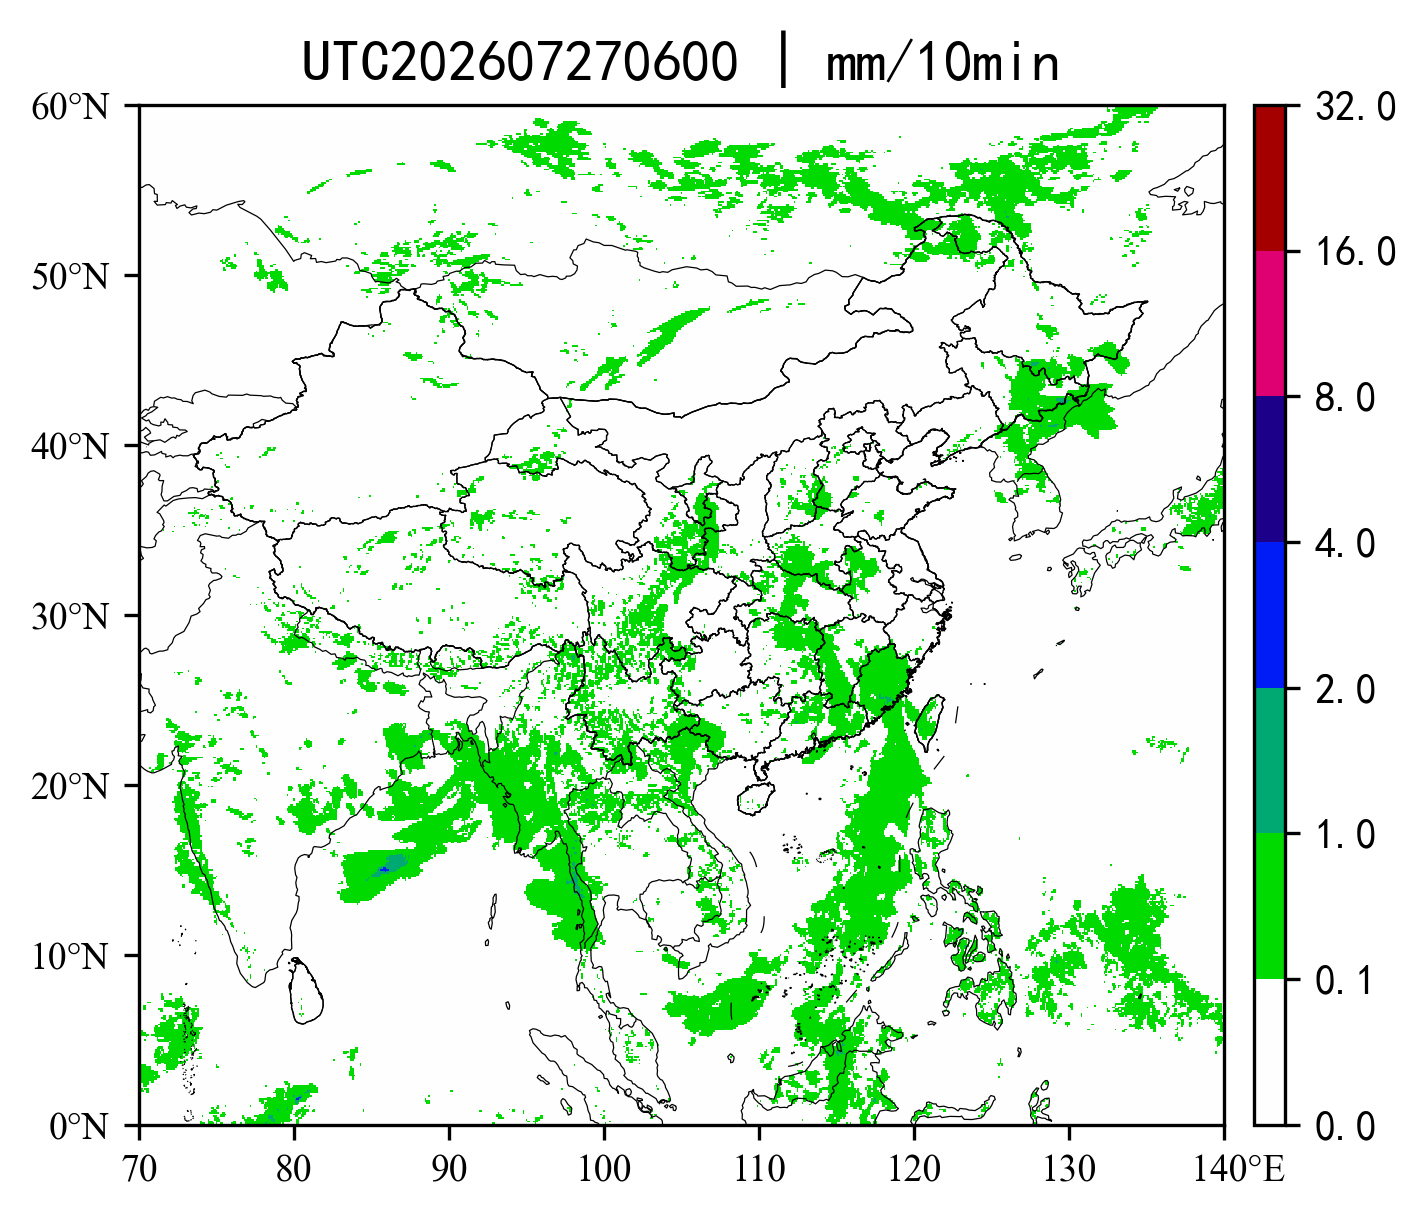

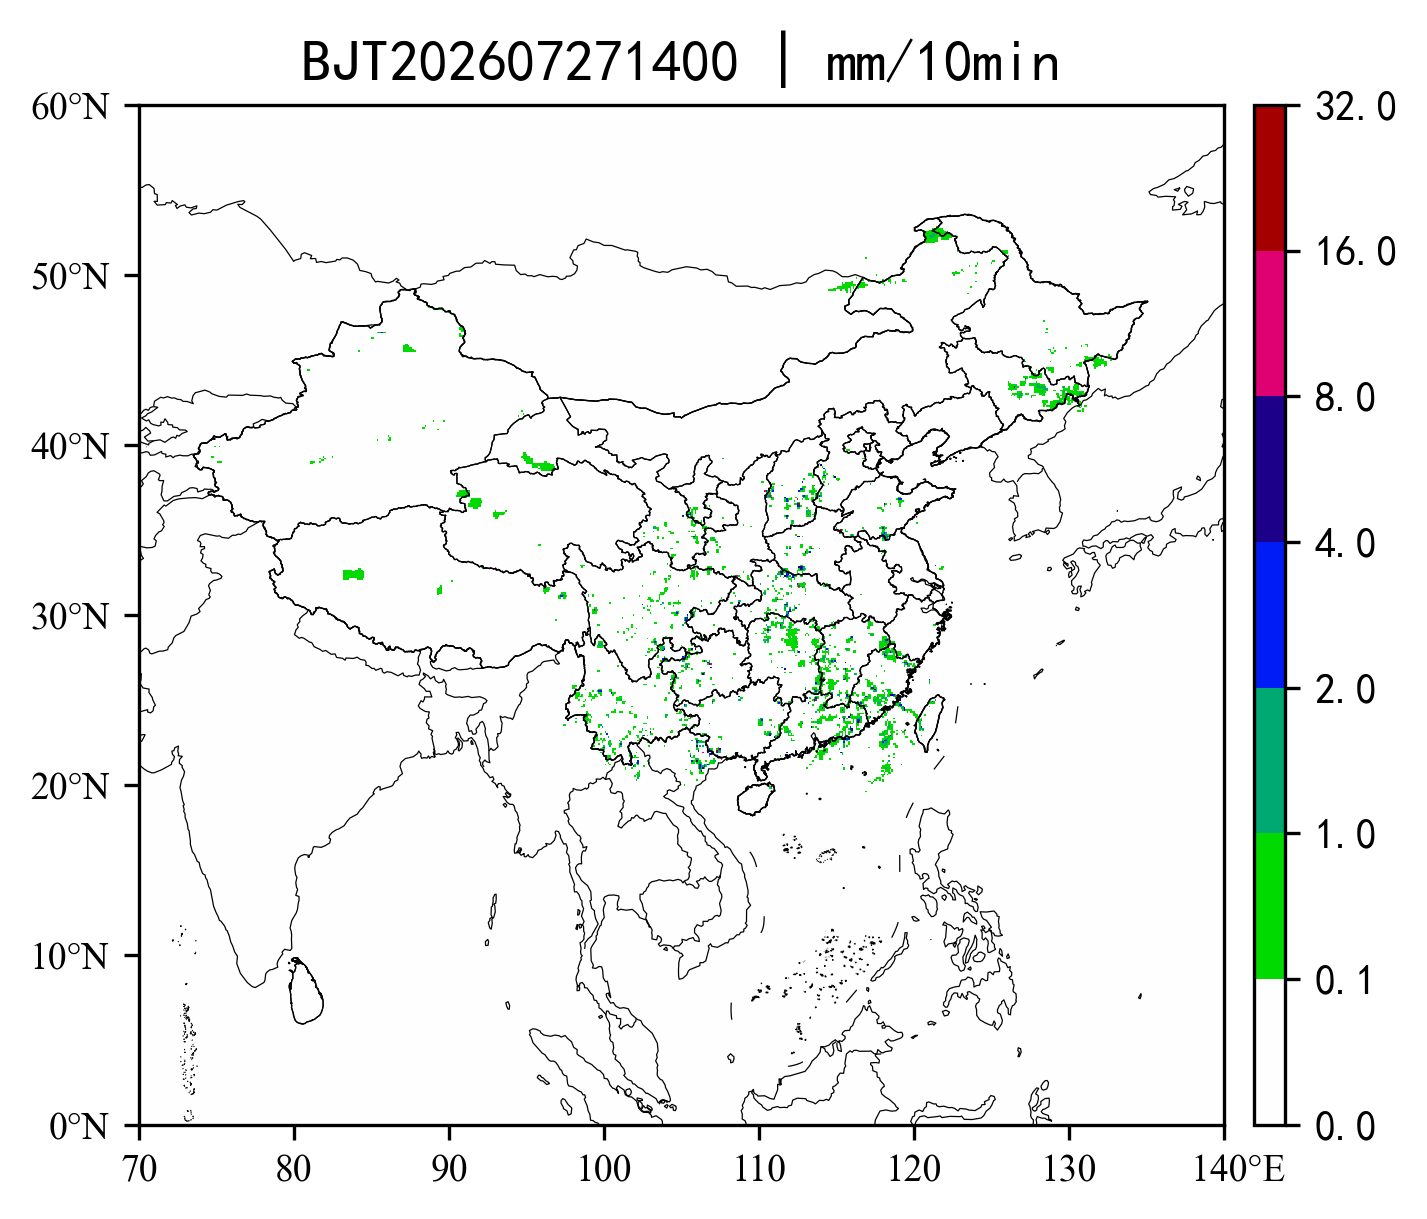

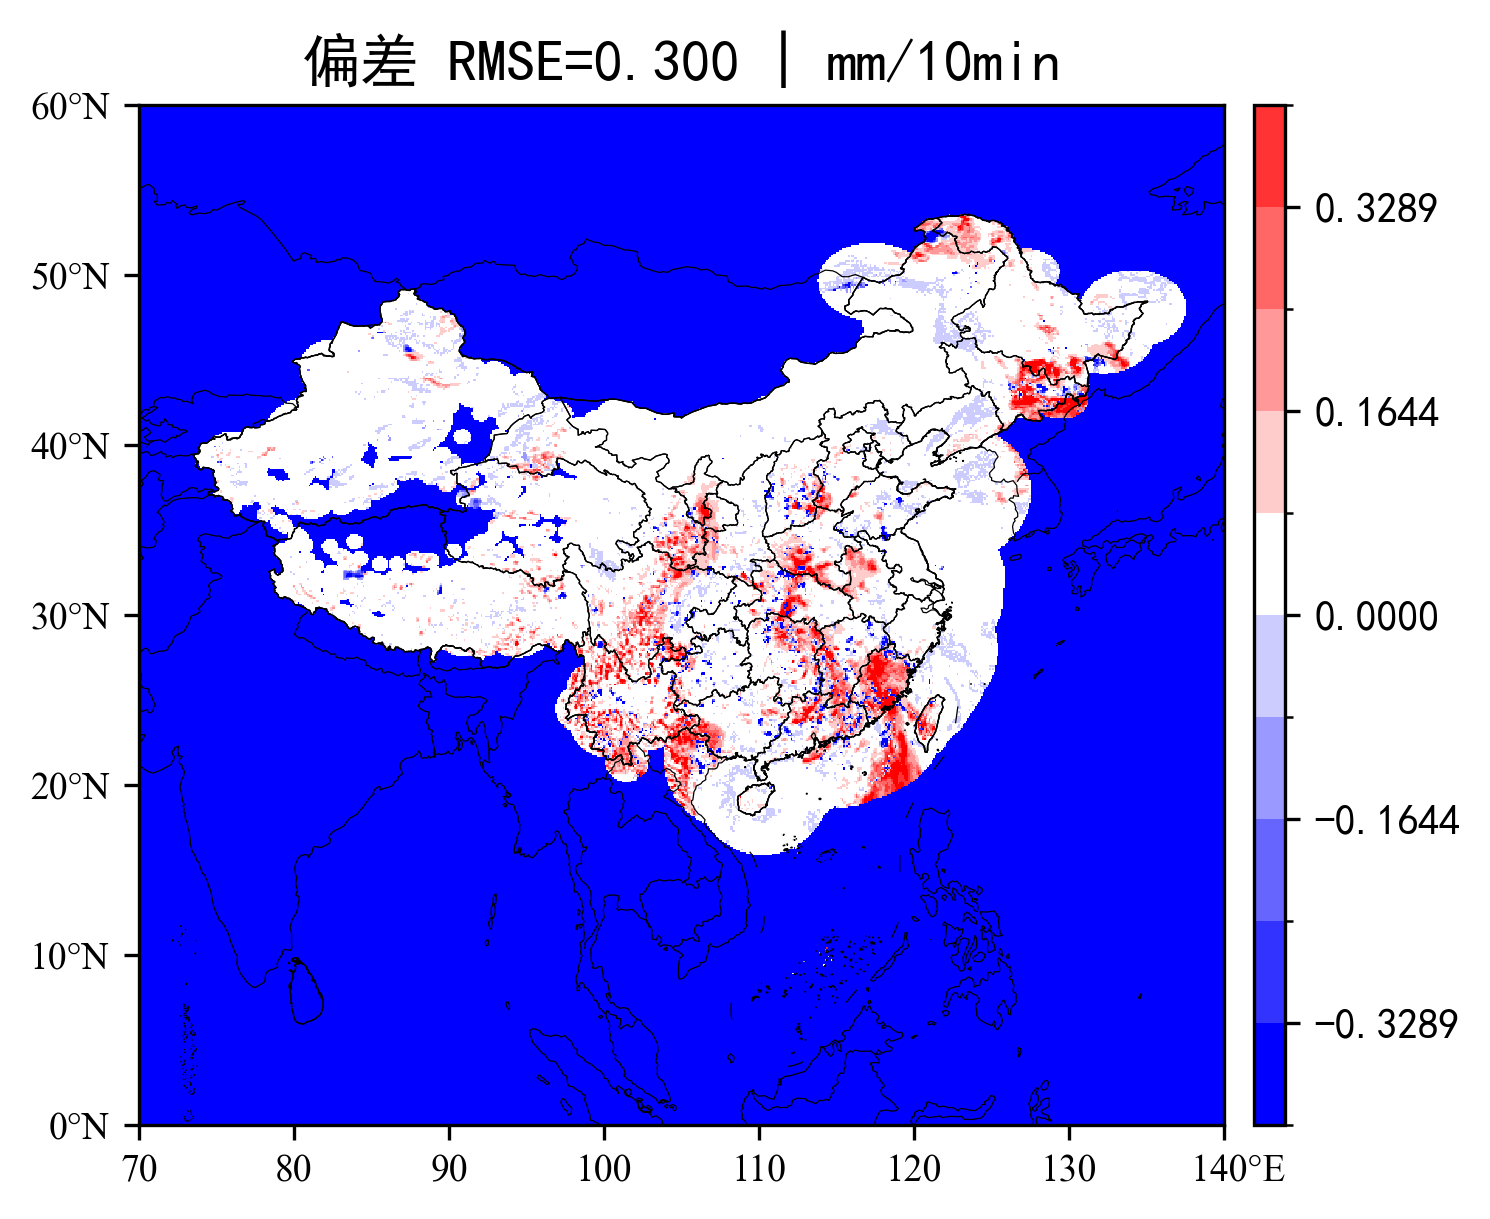

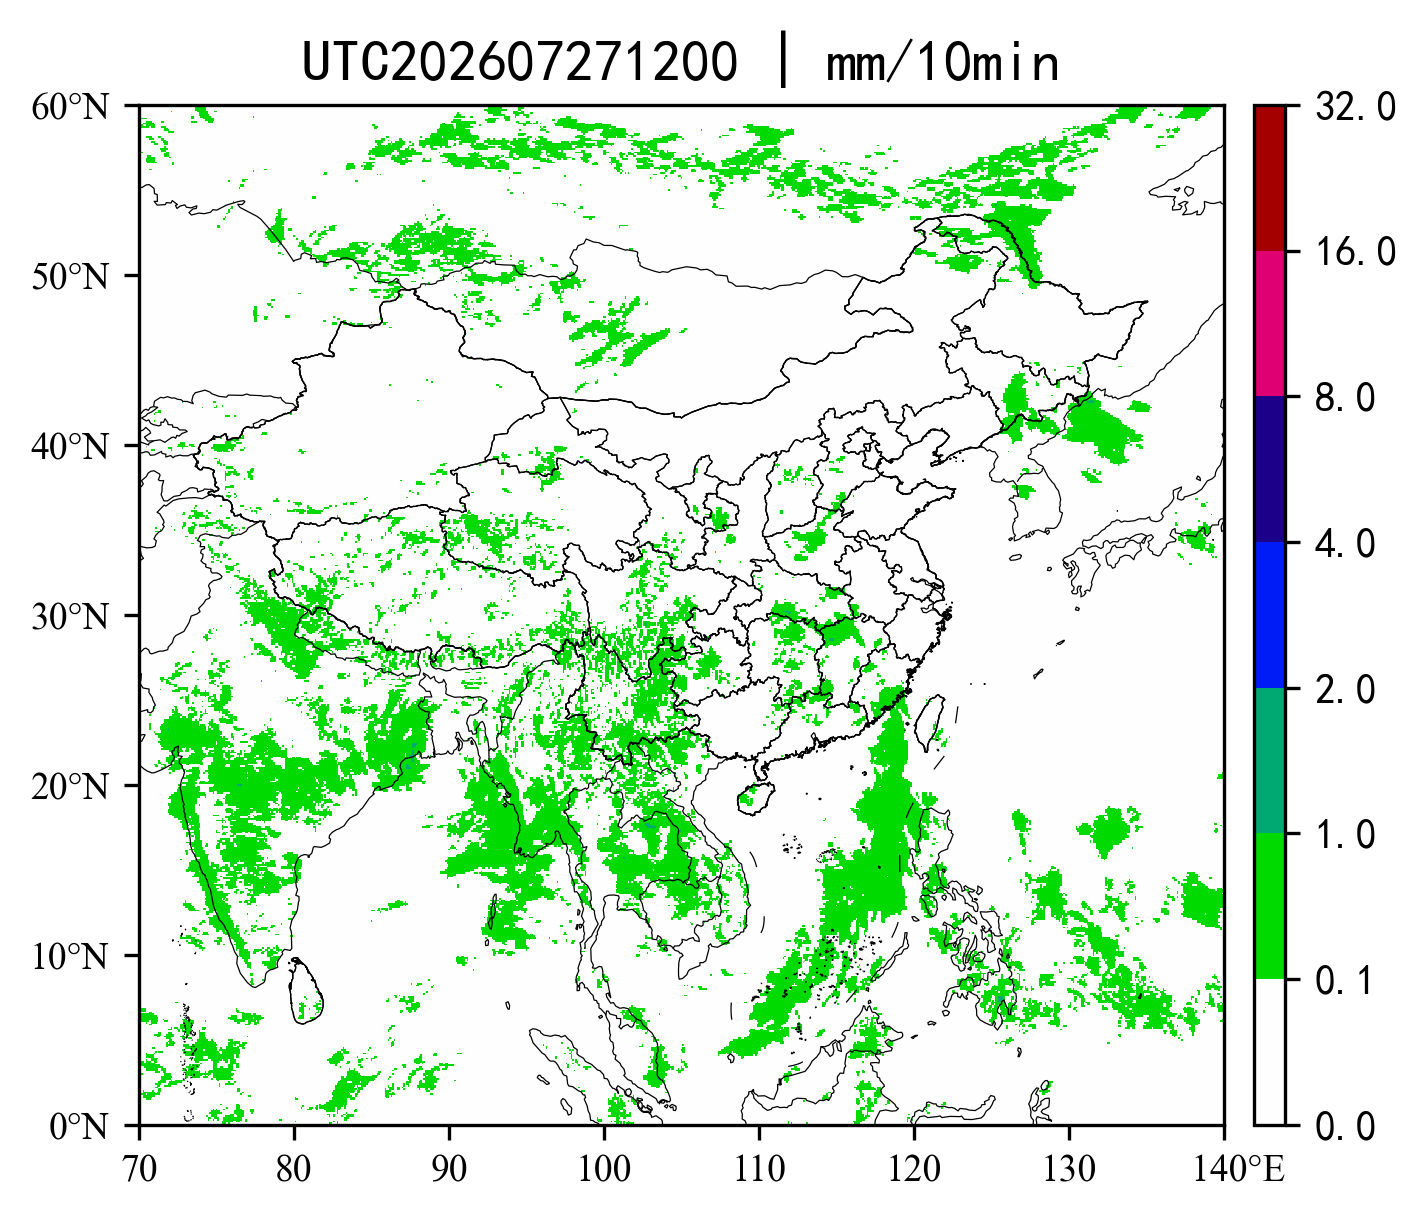

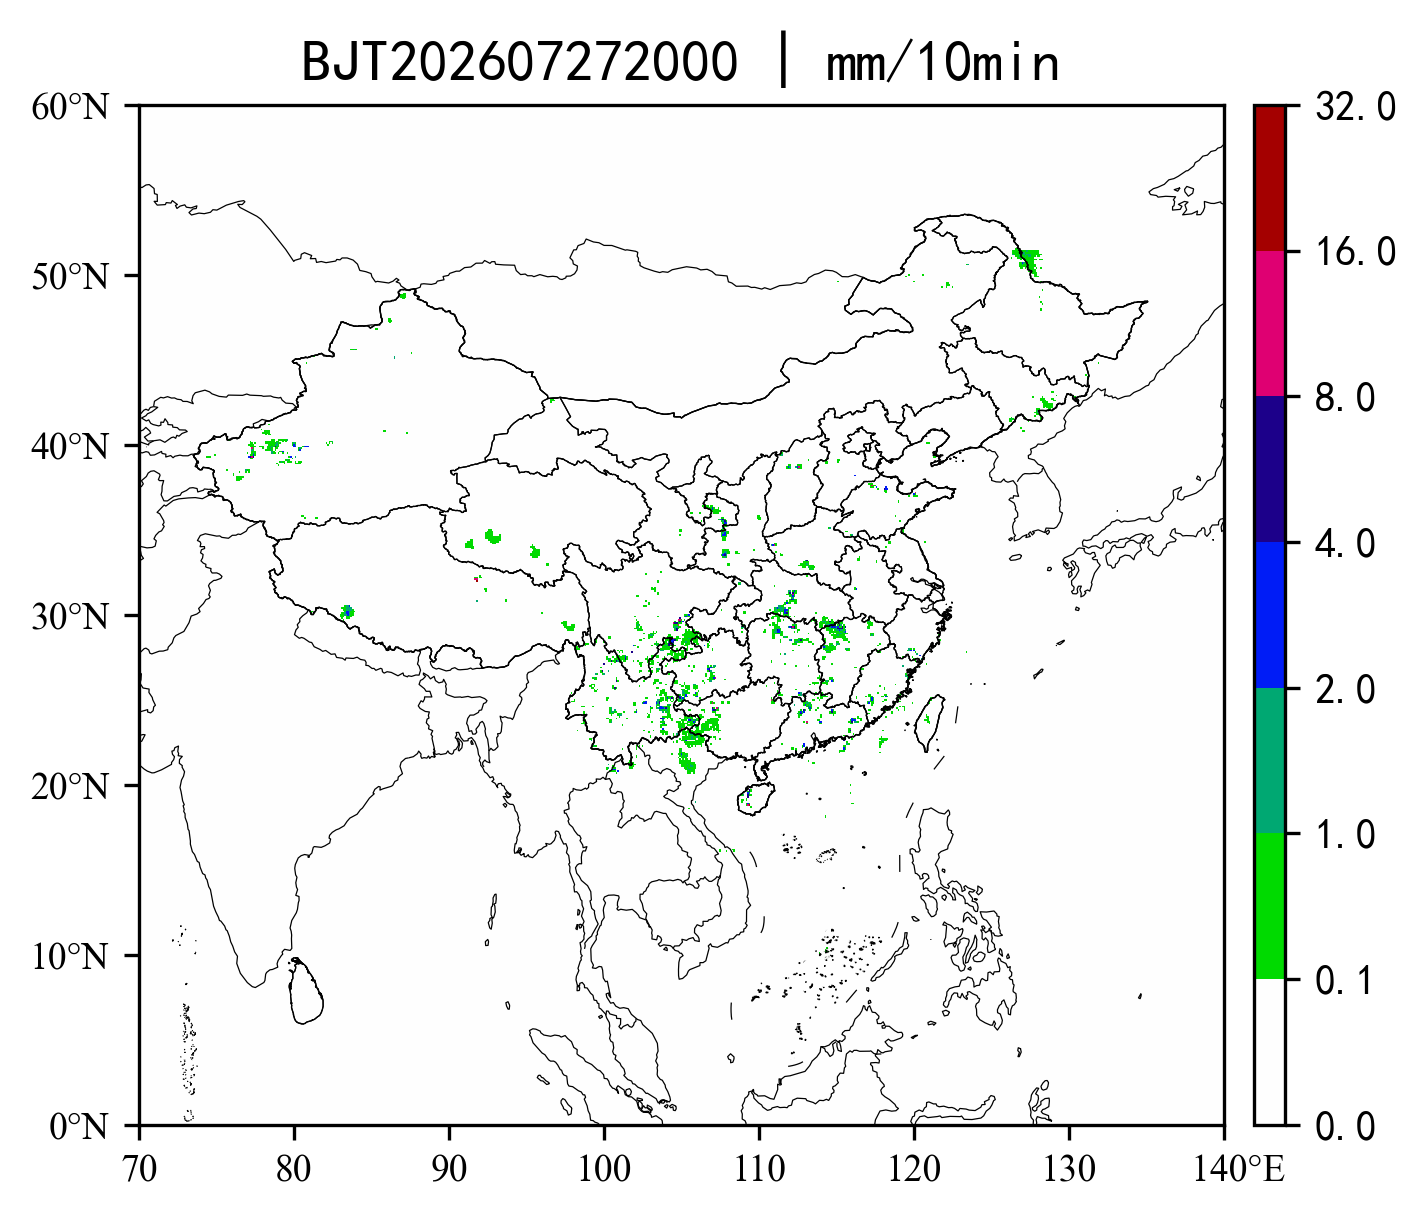

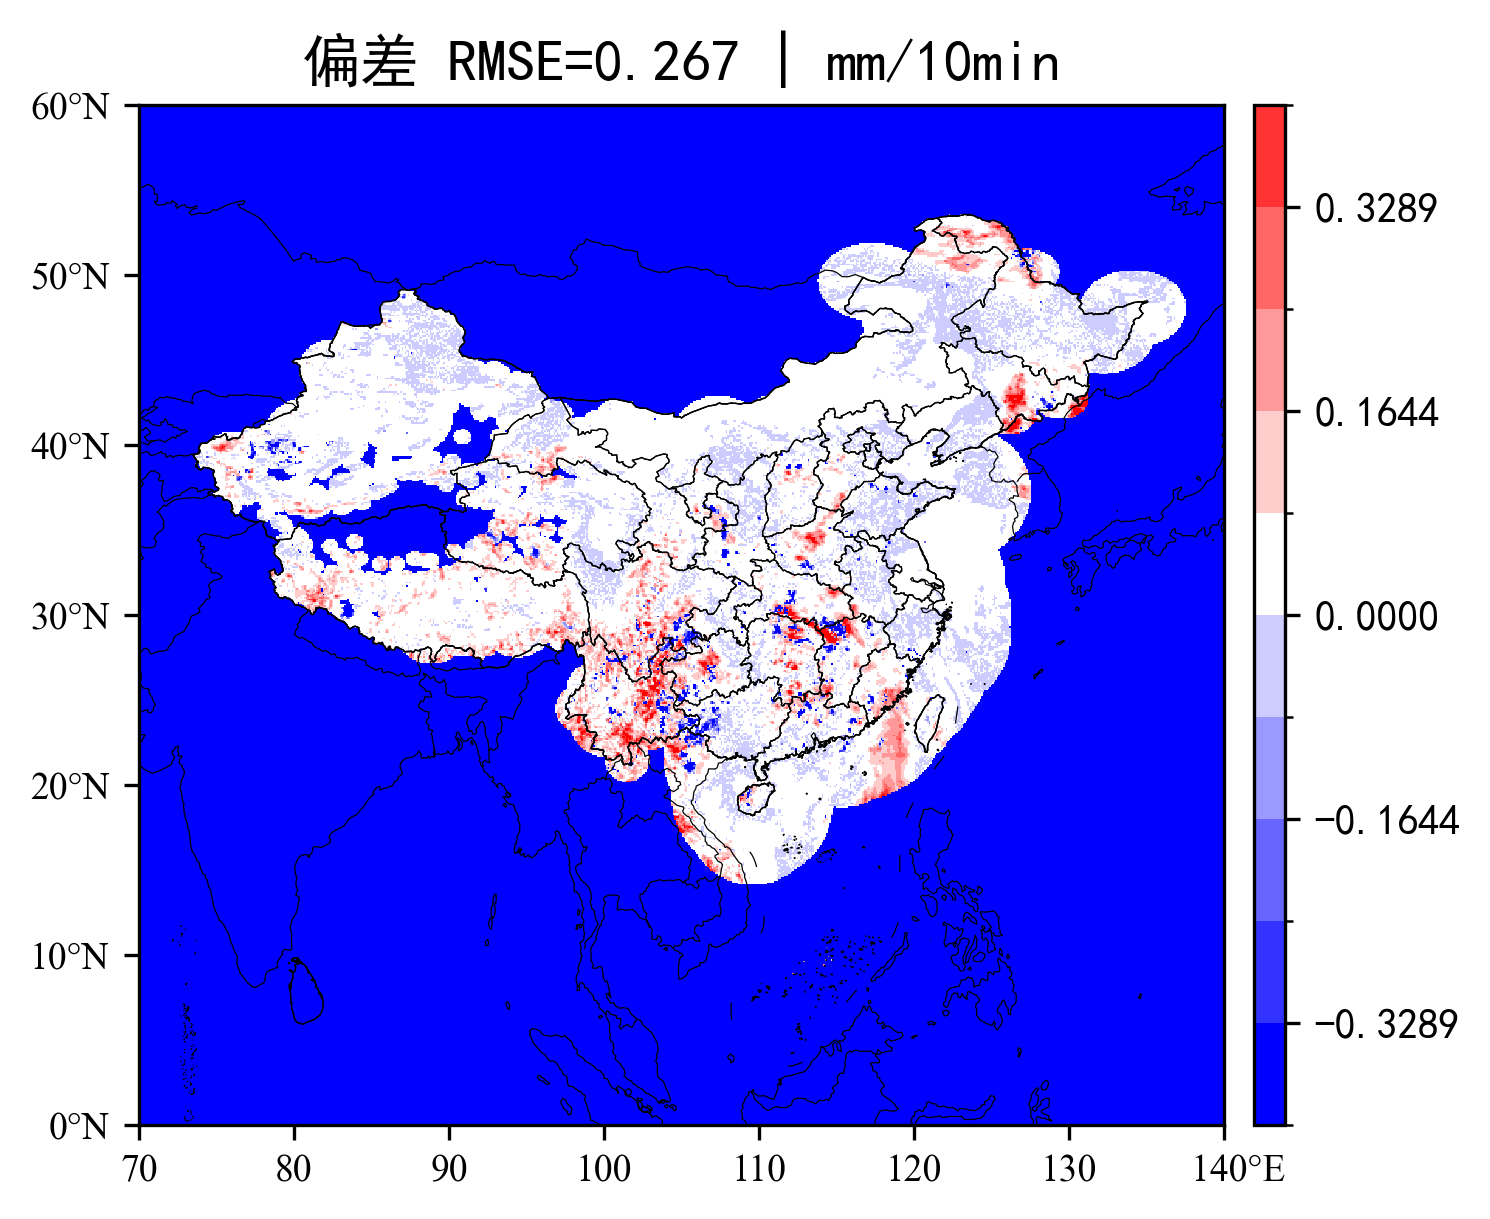

figures -> D:\workspace\test\00temp\time_split_linear\nbs\figs_verify_3h_to_10min


In [8]:
FIG_DIR_MIN = ROOT / "nbs" / "figs_verify_3h_to_10min"
FIG_DIR_MIN.mkdir(parents=True, exist_ok=True)

PLOT_LEADS_MIN = (360, 720)  # UTC 06:00, 12:00 → BJT 14:00, 20:00


def _as_overlap_grid_min(lead_min: int, values_2d: np.ndarray):
    tmpl = fine_min.sel(dtime=lead_min, lon=lon_need_m, lat=lat_need_m)
    out = tmpl.copy(deep=True)
    out.values[:] = np.asarray(values_2d, dtype=np.float32).reshape(out.shape)
    return out


def _show_min(da, title, fname, *, cmap=None, clevs=None):
    field = _plottable(da)
    kw = dict(save_path=str(FIG_DIR_MIN / fname), title=title, clevs=clevs, show=True)
    if cmap is not None:
        kw["cmap"] = cmap
    pcolormesh_2d_grid(field, **kw)


panels_min = []
for lead_min in PLOT_LEADS_MIN:
    if lead_min not in set(map(int, fine_min.dtime.values)):
        print("跳过：fine_min 无", lead_min)
        continue
    op = obs10_path_for_lead_min(lead_min)
    if not op.is_file():
        print("跳过：无实况", op)
        continue
    obs = clean_cmpa10(meb.read_griddata_from_grib(str(op)))
    obs_s = sample_obs_on_fcst_grid(obs, lon_need_m, lat_need_m)
    fc_da = fine_min.sel(dtime=lead_min, lon=lon_need_m, lat=lat_need_m)
    fc_2d = np.squeeze(np.asarray(fc_da.values, dtype=float))
    bjt = ISSUE + timedelta(minutes=int(lead_min) + 8 * 60)
    panels_min.append(
        {
            "lead_min": lead_min,
            "bjt": bjt,
            "fc": fc_da,
            "obs": _as_overlap_grid_min(lead_min, obs_s),
            "diff": _as_overlap_grid_min(lead_min, fc_2d - obs_s),
            "rmse": rmse(fc_2d, obs_s),
        }
    )

assert panels_min, "没有可画的 10min 面板"
rain_clevs_m = _auto_clevs(
    [p["fc"] for p in panels_min] + [p["obs"] for p in panels_min],
    nonnegative=True,
)
bias_clevs_m = _auto_clevs([p["diff"] for p in panels_min], symmetric=True)
print("rain_clevs", rain_clevs_m)
print("bias_clevs", [round(x, 3) for x in bias_clevs_m])

for p in panels_min:
    lm = p["lead_min"]
    bjt = p["bjt"]
    _show_min(
        p["fc"],
        f"UTC{(ISSUE+timedelta(minutes=int(lm))):%Y%m%d%H%M} | mm/10min",
        f"min{lm}_fc.png",
        cmap="rain_1h",
        clevs=rain_clevs_m,
    )
    _show_min(
        p["obs"],
        f"BJT{bjt:%Y%m%d%H%M} | mm/10min",
        f"min{lm}_obs.png",
        cmap="rain_1h",
        clevs=rain_clevs_m,
    )
    _show_min(
        p["diff"],
        f"偏差 RMSE={p['rmse']:.3f} | mm/10min",
        f"min{lm}_bias.png",
        cmap="bwr",
        clevs=bias_clevs_m,
    )

print("figures ->", FIG_DIR_MIN)
